In [1]:
# Make helpers.py importable, whatever folder Jupyter started the kernel in
import sys
from pathlib import Path
_candidates = [Path.cwd(), Path.cwd() / "code",
               *Path.cwd().glob("*/code"), *Path.cwd().glob("*/*/code")]
CODE = next(p for p in _candidates if (p / "helpers.py").is_file())
sys.path.insert(0, str(CODE))

In [2]:
# Generated with Claude (Anthropic): logistic regressions of underfunding on
# sector and country characteristics, with country-clustered standard errors.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

from helpers import find_root, country_folds

ROOT = find_root()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

df = pd.read_csv(PROCESSED / "analysis_table.csv")

# Standardize the country characteristics (mean 0, standard deviation 1),
# so that their effects are comparable: "+1 standard deviation"
for col in ["log_gdp_pc_lag", "gov_effectiveness_lag", "log_reports_lag"]:
    df[col + "_std"] = (df[col] - df[col].mean()) / df[col].std()

REFERENCE_SECTOR = "Food Security"   # best-funded sector: effects are measured against it

CONTROLS = "C(year) + log_requirements"          # year fixed effects + appeal size
SECTOR = f'C(cluster, Treatment(reference="{REFERENCE_SECTOR}"))'
COUNTRY = "log_gdp_pc_lag_std + gov_effectiveness_lag_std + log_reports_lag_std"

formulas = {
    "0. Controls only":    f"underfunded ~ {CONTROLS}",
    "1. Sector":           f"underfunded ~ {SECTOR} + {CONTROLS}",
    "2. Country":          f"underfunded ~ {COUNTRY} + {CONTROLS}",
    "3. Sector + country": f"underfunded ~ {SECTOR} + {COUNTRY} + {CONTROLS}",
}
print(df.shape)

(7413, 21)


In [3]:
# Rows of the same country are not independent: standard errors clustered by country
groups = pd.factorize(df["countryCode"])[0]

models = {}
for name, formula in formulas.items():
    models[name] = smf.logit(formula, data=df).fit(
        disp=False, cov_type="cluster", cov_kwds={"groups": groups})

comparison = pd.DataFrame({
    name: {"Rows": int(m.nobs),
           "Parameters": int(m.df_model) + 1,
           "Pseudo R2 (McFadden)": round(m.prsquared, 3),
           "Log-likelihood": round(m.llf, 1),
           "AIC": round(m.aic, 1)}
    for name, m in models.items()}).T
comparison = comparison.astype({"Rows": int, "Parameters": int})
comparison.to_csv(FIGURES / "table_model_comparison.csv")
comparison

,Rows,Parameters,Pseudo R2 (McFadden),Log-likelihood,AIC
0. Controls only,7413,27,0.031,-4710.0,9473.9
1. Sector,7413,45,0.103,-4361.1,8812.1
2. Country,7413,30,0.038,-4679.4,9418.8
3. Sector + country,7413,48,0.115,-4305.6,8707.2


In [4]:
# Average marginal effects of model 3, in percentage points (pp):
# change in the probability of being underfunded, other variables held equal
m3 = models["3. Sector + country"]
me = m3.get_margeff(at="overall", dummy=True).summary_frame()
me = me[~me.index.str.startswith("C(year)")]      # year effects are controls: not shown

effects = pd.DataFrame({
    "Effect (pp)": 100 * me.iloc[:, 0],
    "95% CI, low": 100 * me.iloc[:, 4],
    "95% CI, high": 100 * me.iloc[:, 5],
    "p-value": me.iloc[:, 3],
})

# Group the rows by type and give readable names
LABELS = {"log_gdp_pc_lag_std": "GDP per capita (+1 SD)",
          "gov_effectiveness_lag_std": "Government effectiveness (+1 SD)",
          "log_reports_lag_std": "Humanitarian attention (+1 SD)",
          "log_requirements": "log requirements"}

def describe(name):
    if name == "log_requirements":
        return "Control", LABELS[name]
    if name in LABELS:
        return "Country characteristic (t-1)", LABELS[name]
    return "Sector (vs Food Security)", name.split("[T.")[1].rstrip("]")

effects.index = pd.MultiIndex.from_tuples([describe(n) for n in effects.index],
                                          names=["Type", "Variable"])
effects = effects.round(2)
effects.to_csv(FIGURES / "table_marginal_effects.csv")

effects.style.set_caption(
    "Average marginal effects on the probability of being underfunded "
    "(percentage points), model 3. Year fixed effects included; "
    "standard errors clustered by country."
).format(precision=2)

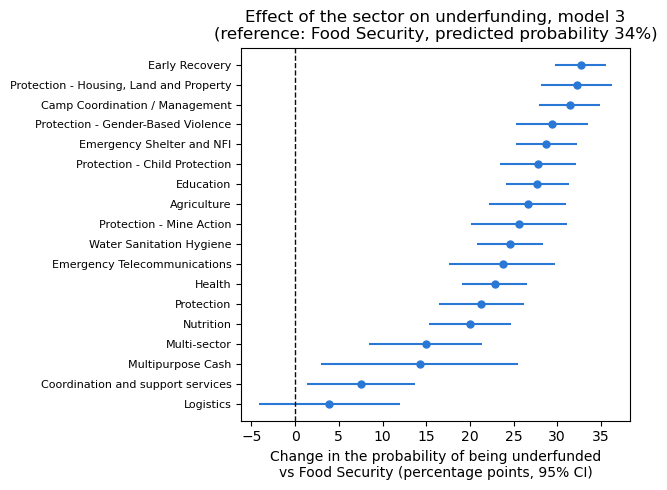

In [5]:
# Effects of the sector, with 95% confidence intervals
BLUE, INK = "#2a78d6", "#0b0b0b"
sectors = effects.loc["Sector (vs Food Security)"].sort_values("Effect (pp)")

# Predicted probability for Food Security (all rows set to Food Security, then averaged)
p_reference = m3.predict(df.assign(cluster=REFERENCE_SECTOR)).mean()

fig, ax = plt.subplots(figsize=(6.5, 5))
y = np.arange(len(sectors))
ax.errorbar(sectors["Effect (pp)"], y,
            xerr=[sectors["Effect (pp)"] - sectors["95% CI, low"],
                  sectors["95% CI, high"] - sectors["Effect (pp)"]],
            fmt="o", color=BLUE, elinewidth=1.5, markersize=5)
ax.axvline(0, color=INK, linewidth=1, linestyle="--")   # 0 = same as Food Security
ax.set_yticks(y, sectors.index, fontsize=8)
ax.set_xlabel("Change in the probability of being underfunded\n"
              "vs Food Security (percentage points, 95% CI)")
ax.set_title("Effect of the sector on underfunding, model 3\n"
             f"(reference: Food Security, predicted probability {p_reference:.0%})")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fig_sector_effects.pdf")
plt.show()

In [6]:
# Grouped 5-fold cross-validation (lecture 4: k-fold cross-validation), with all
# rows of a country in the same fold: models are always tested on unseen countries
df["fold"] = country_folds(df)
print(df.groupby("fold").agg(rows=("id", "size"), countries=("countryCode", "nunique")))

predictions = pd.DataFrame(index=df.index, columns=list(formulas), dtype=float)
for k in sorted(df["fold"].unique()):
    train, test = df[df["fold"] != k], df[df["fold"] == k]
    for name, formula in formulas.items():
        model = smf.logit(formula, data=train).fit(disp=False)
        predictions.loc[test.index, name] = model.predict(test)

cv = pd.DataFrame({
    name: {"AUC": roc_auc_score(df["underfunded"], predictions[name]),
           "Accuracy": ((predictions[name] >= 0.5) == df["underfunded"]).mean()}
    for name in formulas}).T

# Benchmark: always predict "underfunded"
cv.loc["Always 'underfunded'"] = [0.5, df["underfunded"].mean()]
cv = cv.round(3)
cv.to_csv(FIGURES / "table_cv_logit.csv")
cv

      rows  countries
fold                 
0     1481         16
1     1483         17
2     1486         17
3     1483         17
4     1480         16


,AUC,Accuracy
0. Controls only,0.595,0.639
1. Sector,0.688,0.688
2. Country,0.600,0.638
3. Sector + country,0.697,0.688
Always 'underfunded',0.500,0.636
